# 3_Emotion_Reg_CNN

Bản chuyển từ sample **2. CNN + MLP/3_Emotion_Reg_CNN.ipynb**. Chạy các ô theo thứ tự.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import math
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset, Subset
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

FULL = False  # True: dùng dữ liệu và số epoch theo sample
PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "HUONG_DAN.txt").is_file()), Path.cwd())
ROOT = PROJECT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(2018)
torch.set_num_threads(min(4, torch.get_num_threads()))
results = {}

In [2]:
def epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = correct = units = 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            out = model(x)
            if isinstance(criterion, nn.CrossEntropyLoss):
                assert out.argmax(1).shape == y.shape and y.dtype == torch.long
                correct += (out.argmax(1) == y).sum().item()
            else:
                assert out.shape == y.shape
            loss = criterion(out, y)
            if not torch.isfinite(loss):
                raise ValueError("Loss không hữu hạn")
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.numel()
            units += y.numel()
    return total_loss / units, correct / units

def fit(name, model, train, valid, criterion, opt, lr, epochs, batch,
        early=False, schedule=False, checkpoint=False, verbose=True):
    for layer in model.modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    model.to(DEVICE)
    writer = None
    if checkpoint:
        from torch.utils.tensorboard import SummaryWriter
        writer = SummaryWriter("logs/" + name)
    optimizer = opt(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.1, patience=4, min_lr=1e-4,
        threshold=1e-4, threshold_mode="abs")
    loaders = [DataLoader(train, batch, shuffle=True), DataLoader(valid, batch)]
    best, stale = float("inf"), 0
    for step in range(1, epochs + 1):
        train_loss, _ = epoch(model, loaders[0], criterion, optimizer)
        val_loss, accuracy = epoch(model, loaders[1], criterion)
        if writer:
            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/validation", val_loss, step)
            writer.add_scalar("accuracy/validation", accuracy, step)
        if val_loss < best:
            best, stale = val_loss, 0
            if checkpoint:
                torch.save(model.state_dict(), f"{name}_best.pt")
        else:
            stale += 1
        if schedule:
            scheduler.step(val_loss)
        if early and stale >= 5:
            break
    if writer:
        writer.close()
    if checkpoint:
        model.load_state_dict(torch.load(f"{name}_best.pt", map_location=DEVICE,
                                         weights_only=True))
        val_loss, accuracy = epoch(model, loaders[1], criterion)
    metric = accuracy if isinstance(criterion, nn.CrossEntropyLoss) else val_loss
    results[name] = (len(train), len(valid), step, val_loss, metric)
    if verbose:
        print(f"{name} | {step} epoch | train loss {train_loss:.5f} | "
              f"val loss {val_loss:.5f}", end="")
        if isinstance(criterion, nn.CrossEntropyLoss):
            print(f" | accuracy {accuracy:.2%}", end="")
        print()
    return model

FULL=False kiểm tra trên ảnh giả lập. FULL=True đọc dữ liệu thật từ data theo tên trong hàm bên dưới. Cấu hình cơ sở.

In [3]:
def head(n_in, hidden, n_out, dropout):
    layers = [nn.Flatten()]
    for width in hidden:
        layers.extend([nn.Linear(n_in, width), nn.ReLU(), nn.Dropout(dropout)])
        n_in = width
    return nn.Sequential(*layers, nn.Linear(n_in, n_out))

def conv_block(n_in, channels, paddings, dropout):
    layers = []
    for width, padding in zip(channels, paddings, strict=True):
        layers.extend([nn.Conv2d(n_in, width, 3, padding=padding), nn.ReLU()])
        n_in = width
    return nn.Sequential(*layers, nn.MaxPool2d(2), nn.Dropout(dropout))

def emotion_net():
    return nn.Sequential(conv_block(1, [64, 64], [1, 0], 0.25),
                         conv_block(64, [128, 128, 218, 218], [1, 0, 1, 0], 0.25),
                         head(218 * 9 * 9, [1024], 7, 0.5))

def emotion_data(split):
    data = np.loadtxt(ROOT / f"fer2013_{split}_onehot.csv", delimiter=",",
                      dtype=np.float32, ndmin=2)
    assert data.shape[1] == 2311
    return TensorDataset(torch.from_numpy(data[:, :2304]).reshape(-1, 1, 48, 48),
                         torch.from_numpy(data[:, 2304:].argmax(1)).long())

def mock_images(side, classes, count=2):
    return TensorDataset(torch.rand(count, 1, side, side), torch.arange(count) % classes)

Kiểm tra bằng ảnh và nhãn giả lập
emotion | 1 epoch | train loss 1.93879 | val loss 1.90187 | accuracy 50.00%
Nhãn 0 | dự đoán 0


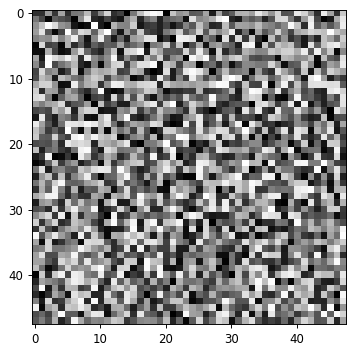

In [4]:
if FULL:
    train = emotion_data("training")
    valid = emotion_data("publictest")
else:
    print("Kiểm tra bằng ảnh và nhãn giả lập")
    train = mock_images(48, 7)
    valid = mock_images(48, 7)
model = fit("emotion", emotion_net(), train, valid, nn.CrossEntropyLoss(), torch.optim.Adam,
            0.0001, 15 if FULL else 1, 128 if FULL else 2, early=False,
            schedule=False, checkpoint=False and FULL)
x, y = valid[0]
with torch.inference_mode():
    pred = model(x[None].to(DEVICE)).argmax(1).item()
print("Nhãn", y.item(), "| dự đoán", pred)
plt.imshow(x.squeeze(), cmap="gray")
plt.show()